# Experiment 07 — Real-World Robustness

## E6 — Koopman Stability Analysis

### 1. Mục tiêu

Đánh giá tính ổn định của động lực học trong không gian tiềm ẩn (*latent dynamics*) được học bởi DeepKoopFormer.

Thực nghiệm tập trung kiểm tra ảnh hưởng của toán tử Koopman và phương pháp chính quy hóa Lyapunov đến tính ổn định của mô hình.

### 2. Thiết kế thực nghiệm

**Datasets:**
- Electricity — 6 channels.
- CMIP6 Wind — 5 channels.

**Models:**
- PatchTST_LinearLatent.
- KoopPatchTST_NoLyap.
- KoopPatchTST_Full.

Sử dụng các checkpoint đã huấn luyện trong Ablation với cùng cấu hình:

| Tham số | Giá trị |
|---|---|
| Input Sequence Length | 120 |
| Forecast Horizon | 8 |
| Epochs đã huấn luyện | 4000 |
| Training Seed | 7 |
| Evaluation Mode | Inference & Operator Analysis |
| Training bổ sung | 0 |

### 3. Nội dung phân tích

**E6.1 — Koopman Operator Spectrum**

- Tính Spectral Radius của toán tử tuyến tính trong latent space.
- Tính Maximum Singular Value.
- Kiểm tra mức độ thỏa mãn điều kiện ổn định tương ứng với từng kiến trúc.

**E6.2 — Latent Dynamics Stability**

- Theo dõi sự thay đổi chuẩn của latent state qua nhiều bước biến đổi.
- Phân tích mức tăng hoặc giảm của năng lượng latent.
- So sánh động lực học giữa các biến thể mô hình.

**E6.3 — Lyapunov Regularization Analysis**

- Kiểm tra các đại lượng liên quan đến điều kiện ổn định Lyapunov.
- So sánh KoopPatchTST_NoLyap và KoopPatchTST_Full.
- Đánh giá ảnh hưởng của chính quy hóa Lyapunov đến đặc điểm động lực học đã học.

### 4. Chỉ số đánh giá

- Spectral Radius: \(\rho(K)\).
- Maximum Singular Value: \(\sigma_{\max}(K)\).
- Latent State Norm: \(\|z_t\|_2\).
- Latent Energy: \(\|z_t\|_2^2\).
- Các chỉ số Lyapunov phù hợp với định nghĩa trong mô hình gốc.

### 5. Quy trình thực hiện

1. Nạp các checkpoint đã huấn luyện từ Ablation.
2. Kiểm tra cấu hình và toán tử động lực học của từng mô hình.
3. Phân tích phổ và singular values của toán tử.
4. Mô phỏng sự tiến triển của latent states.
5. Kiểm tra các đại lượng liên quan đến chính quy hóa Lyapunov.
6. Tổng hợp kết quả và trực quan hóa.

### 6. Kết quả đầu ra

- `operator_metrics.csv` — Các chỉ số phổ và chuẩn toán tử.
- `latent_dynamics.csv` — Kết quả phân tích tiến triển latent states.
- Các biểu đồ eigenvalue, singular value và latent energy.
- Các bảng so sánh đặc điểm ổn định giữa các biến thể mô hình.

**Training bổ sung: 0 — Analysis Only.**

Các kết quả được sử dụng để đánh giá tính ổn định của động lực học tiềm ẩn và vai trò của chính quy hóa Lyapunov trong DeepKoopFormer.

PRETRAINED CHECKPOINT VERIFICATION

In [1]:
from pathlib import Path
import re
import torch
import pandas as pd

PROJECT = Path(r"C:\Users\Win 11 New\Desktop\pa gk")

ABLATION_RESULTS = (
    PROJECT
    / "experiments"
    / "05_ablation"
    / "results"
    / "ablation_merged_1344"
)

DATASETS = [
    "Electricity",
    "CMIP6 Wind"
]

MODELS = [
    "PatchTST+LinearLatent",
    "KoopPatchTST_NoLyap",
    "KoopPatchTST_Full"
]

P = 120
H = 8
EPOCHS = 4000
SEED = 7


def slug(name):
    return re.sub(
        r"[^a-z0-9]+", "_", name.lower()
    ).strip("_")


rows = []

for dataset in DATASETS:
    for model in MODELS:

        folder = (
            ABLATION_RESULTS
            / f"{slug(dataset)}_grid_search_e4000"
        )

        filename = (
            f"{slug(model)}_p{P}_h{H}_d96.pt"
        )

        path = folder / filename

        assert path.is_file(), (
            f"Checkpoint missing: {path}"
        )

        artifact = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        cfg = artifact["config"]

        assert cfg["dataset"] == dataset
        assert cfg["model"] == model
        assert int(cfg["p"]) == P
        assert int(cfg["h"]) == H
        assert int(cfg["epochs"]) == EPOCHS
        assert int(cfg["seed"]) == SEED

        assert "model_state_dict" in artifact

        state = artifact["model_state_dict"]

        if model == "PatchTST+LinearLatent":
            assert "koop.W.weight" in state
        else:
            assert all(
                key in state
                for key in [
                    "koop.U_raw",
                    "koop.V_raw",
                    "koop.S_raw"
                ]
            )

        rows.append({
            "Dataset": dataset,
            "Model": model,
            "Input_Length": P,
            "Horizon": H,
            "Epochs": EPOCHS,
            "Seed": SEED,
            "File_MB": round(
                path.stat().st_size / 1024**2, 2
            ),
            "Status": "VERIFIED"
        })

        del artifact


E6_CHECKPOINTS = pd.DataFrame(rows)

assert len(E6_CHECKPOINTS) == 6

print("=== E6 PRETRAINED CHECKPOINT AUDIT ===")

display(E6_CHECKPOINTS)

print("\nVERIFIED: 6/6 checkpoints")
print("TRAINING PERFORMED: 0")
print("FILES MODIFIED: 0")
print("\nE6 CHECKPOINT VERIFICATION PASSED")


=== E6 PRETRAINED CHECKPOINT AUDIT ===


c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


,Dataset,Model,Input_Length,Horizon,Epochs,Seed,File_MB,Status
0,Electricity,PatchTST+LinearLatent,120,8,4000,7,2.23,VERIFIED
1,Electricity,KoopPatchTST_NoLyap,120,8,4000,7,2.27,VERIFIED
2,Electricity,KoopPatchTST_Full,120,8,4000,7,2.27,VERIFIED
3,CMIP6 Wind,PatchTST+LinearLatent,120,8,4000,7,1.81,VERIFIED
4,CMIP6 Wind,KoopPatchTST_NoLyap,120,8,4000,7,1.84,VERIFIED
5,CMIP6 Wind,KoopPatchTST_Full,120,8,4000,7,1.84,VERIFIED



VERIFIED: 6/6 checkpoints
TRAINING PERFORMED: 0
FILES MODIFIED: 0

E6 CHECKPOINT VERIFICATION PASSED


OPERATOR SPECTRUM ANALYSIS

In [2]:
import numpy as np
import pandas as pd
import torch

from pathlib import Path

# Reuse configuration from Cell 1:
# PROJECT, ABLATION_RESULTS, DATASETS, MODELS
# P=120, H=8, EPOCHS=4000, SEED=7, slug()

E6_RESULTS = (
    PROJECT
    / "experiments"
    / "07_real_world_robustness"
    / "results"
    / "e6_stability"
)

E6_RESULTS.mkdir(
    parents=True,
    exist_ok=True
)


def load_e6_operator(dataset, model):

    folder = (
        ABLATION_RESULTS
        / f"{slug(dataset)}_grid_search_e4000"
    )

    path = (
        folder
        / f"{slug(model)}_p{P}_h{H}_d96.pt"
    )

    assert path.is_file(), path

    artifact = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    cfg = artifact["config"]

    assert cfg["dataset"] == dataset
    assert cfg["model"] == model
    assert int(cfg["p"]) == 120
    assert int(cfg["h"]) == 8
    assert int(cfg["epochs"]) == 4000
    assert int(cfg["seed"]) == 7

    state = artifact["model_state_dict"]

    with torch.inference_mode():

        if model == "PatchTST+LinearLatent":

            # nn.Linear(z) = z @ W.T
            # Column-vector operator K = W
            K = state[
                "koop.W.weight"
            ].detach().cpu().clone()

            rho_max = None

        else:

            U_raw = state[
                "koop.U_raw"
            ].detach().cpu()

            V_raw = state[
                "koop.V_raw"
            ].detach().cpu()

            S_raw = state[
                "koop.S_raw"
            ].detach().cpu()

            rho_max = float(cfg["rho_max"])

            assert np.isclose(
                rho_max, 0.99
            )

            # Match the trained model's
            # orthogonal-diagonal-orthogonal
            # parameterization.
            U = torch.linalg.qr(U_raw).Q
            V = torch.linalg.qr(V_raw).Q

            sigma = (
                torch.sigmoid(S_raw)
                * rho_max
            )

            K = (
                U
                @ torch.diag(sigma)
                @ V.T
            )

    assert K.shape == (96, 96)
    assert torch.isfinite(K).all()

    # Float64 for numerical spectrum analysis
    return K.double(), rho_max


# ------------------------------------------------------------
# Analyze all 6 pretrained operators
# ------------------------------------------------------------

rows = []

# Retain spectra in memory for subsequent figures
E6_SPECTRA = {}

for dataset in DATASETS:
    for model in MODELS:

        K, rho_max = load_e6_operator(
            dataset, model
        )

        eigenvalues = torch.linalg.eigvals(K)
        singular_values = torch.linalg.svdvals(K)

        spectral_radius = float(
            eigenvalues.abs().max()
        )

        sigma_max = float(
            singular_values.max()
        )

        sigma_min = float(
            singular_values.min()
        )

        # Maximum over unit vectors z:
        # ||Kz||² - ||z||²
        worst_energy_change = (
            sigma_max**2 - 1.0
        )

        schur_stable = spectral_radius < 1.0
        contraction = sigma_max < 1.0

        if rho_max is not None:
            assert sigma_max < rho_max + 1e-5, (
                f"Stable Koopman bound failed: "
                f"{dataset} / {model}"
            )

        assert (
            spectral_radius <= sigma_max + 1e-8
        )

        E6_SPECTRA[(dataset, model)] = {
            "eigenvalues": eigenvalues.numpy(),
            "singular_values": singular_values.numpy(),
            "K": K.numpy()
        }

        rows.append({
            "Dataset": dataset,
            "Model": model,
            "PatchLen": P,
            "Horizon": H,
            "Epochs": EPOCHS,
            "Seed": SEED,
            "Spectral_Radius": spectral_radius,
            "Sigma_Max": sigma_max,
            "Sigma_Min": sigma_min,
            "Worst_Unit_Energy_Change":
                worst_energy_change,
            "Schur_Stable": schur_stable,
            "Euclidean_Contraction": contraction,
            "Rho_Max": rho_max
        })


OPERATOR_METRICS = pd.DataFrame(rows)

assert len(OPERATOR_METRICS) == 6

assert OPERATOR_METRICS[
    ["Spectral_Radius", "Sigma_Max", "Sigma_Min"]
].notna().all().all()

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

OUTPUT_PATH = (
    E6_RESULTS / "operator_metrics.csv"
)

OPERATOR_METRICS.to_csv(
    OUTPUT_PATH,
    index=False
)

print("=== E6.1 OPERATOR SPECTRUM ===")

display(
    OPERATOR_METRICS[[
        "Dataset",
        "Model",
        "Spectral_Radius",
        "Sigma_Max",
        "Worst_Unit_Energy_Change",
        "Schur_Stable",
        "Euclidean_Contraction"
    ]].round(8)
)

print("\n=== STABILITY SUMMARY ===")

display(
    OPERATOR_METRICS.groupby(
        "Model"
    ).agg(
        Runs=("Dataset", "count"),
        Schur_Stable=("Schur_Stable", "sum"),
        Contractive=(
            "Euclidean_Contraction", "sum"
        ),
        Max_Sigma=("Sigma_Max", "max")
    ).round(8)
)

print("\nCHECKPOINTS ANALYZED: 6/6")
print("TRAINING PERFORMED: 0")
print("RESULT SAVED:", OUTPUT_PATH)
print("\nE6.1 OPERATOR SPECTRUM PASSED!")


=== E6.1 OPERATOR SPECTRUM ===


,Dataset,Model,Spectral_Radius,Sigma_Max,Worst_Unit_Energy_Change,Schur_Stable,Euclidean_Contraction
0,Electricity,PatchTST+LinearLatent,0.567698,1.177851,0.387332,True,False
1,Electricity,KoopPatchTST_NoLyap,0.532888,0.889320,-0.209110,True,True
2,Electricity,KoopPatchTST_Full,0.527259,0.889344,-0.209067,True,True
3,CMIP6 Wind,PatchTST+LinearLatent,0.577235,1.151456,0.325851,True,False
4,CMIP6 Wind,KoopPatchTST_NoLyap,0.582295,0.875728,-0.233101,True,True
5,CMIP6 Wind,KoopPatchTST_Full,0.567420,0.875527,-0.233452,True,True



=== STABILITY SUMMARY ===


,Runs,Schur_Stable,Contractive,Max_Sigma
Model,,,,
KoopPatchTST_Full,2,2,2,0.889344
KoopPatchTST_NoLyap,2,2,2,0.889320
PatchTST+LinearLatent,2,2,0,1.177851



CHECKPOINTS ANALYZED: 6/6
TRAINING PERFORMED: 0
RESULT SAVED: C:\Users\Win 11 New\Desktop\pa gk\experiments\07_real_world_robustness\results\e6_stability\operator_metrics.csv

E6.1 OPERATOR SPECTRUM PASSED!


OPERATOR SPECTRUM VISUALIZATION
E6.1 — EIGENVALUES & SINGULAR VALUES

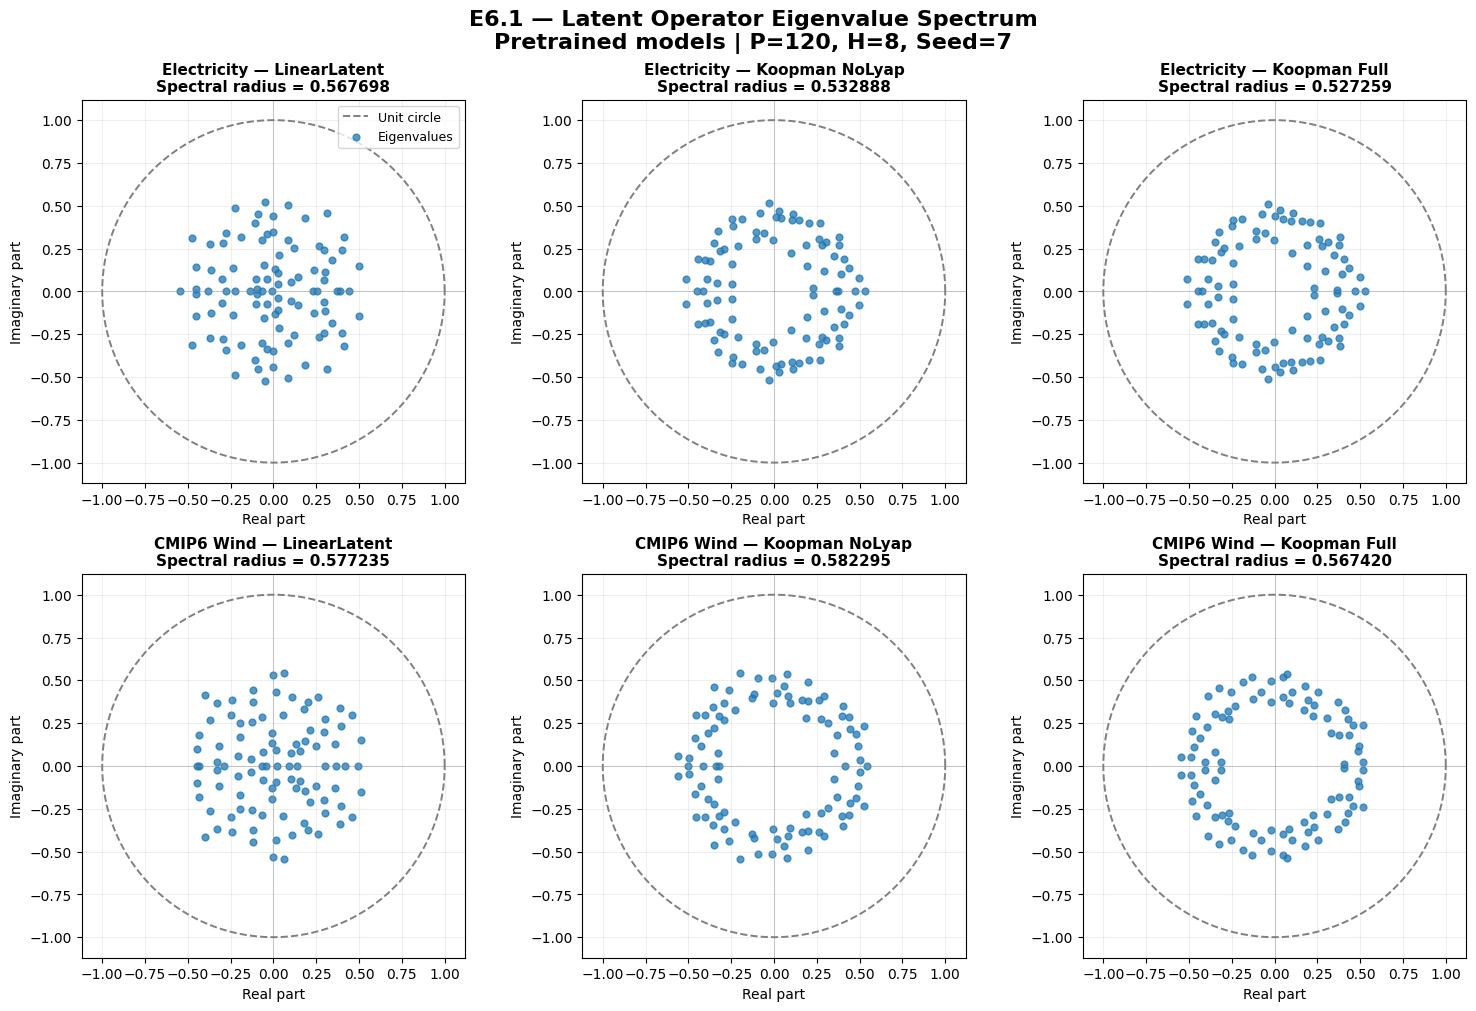

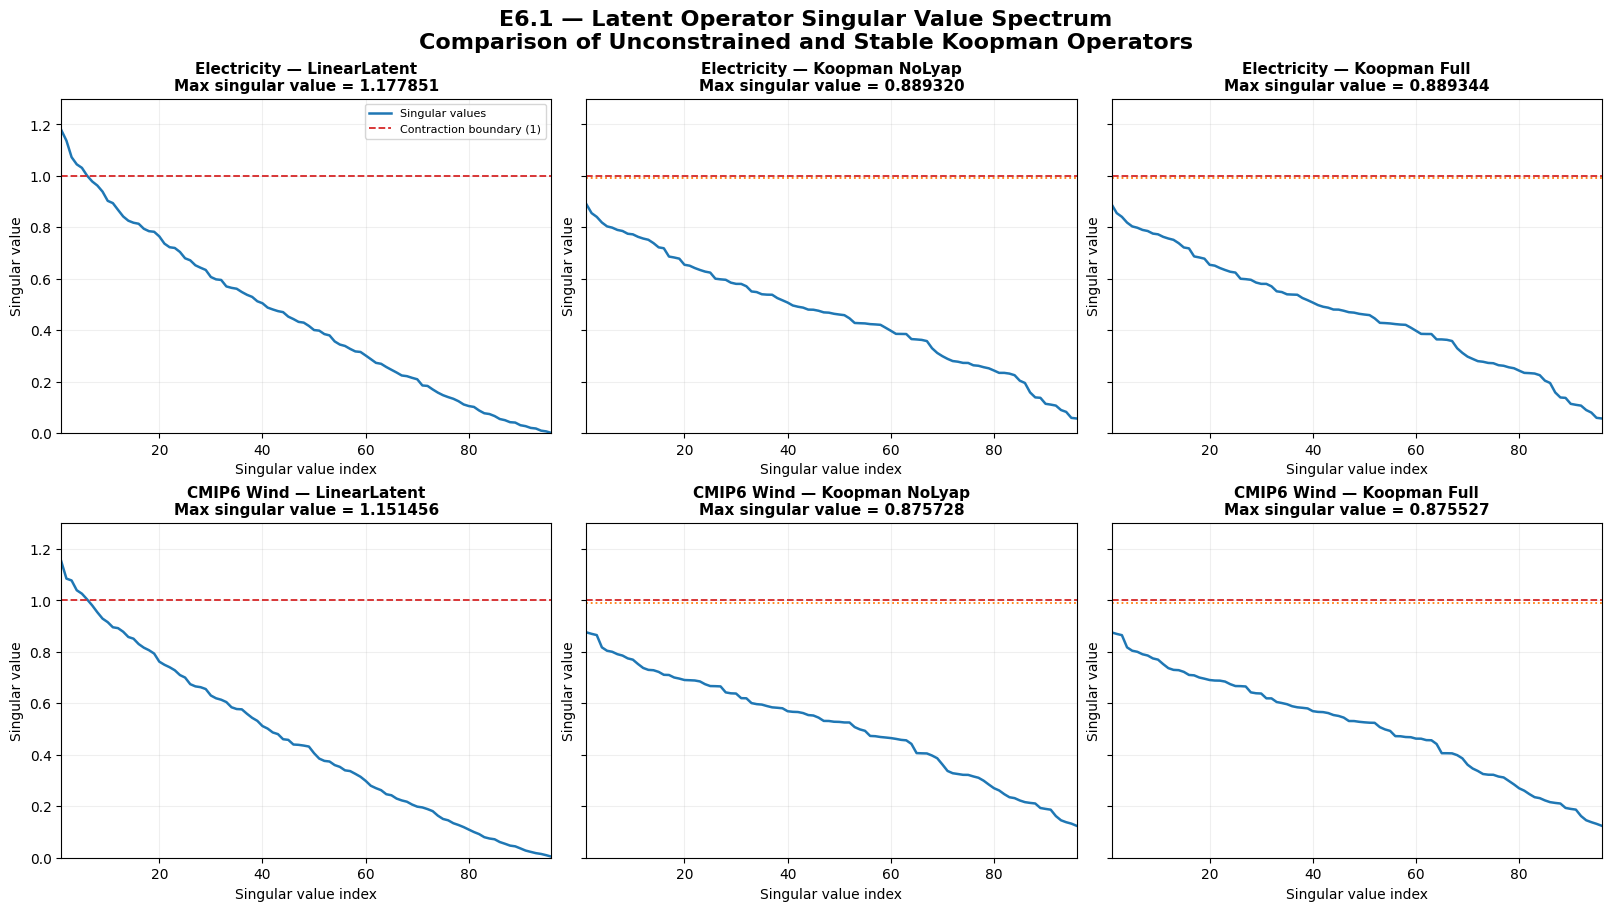


=== E6.1 VISUALIZATION VALIDATION ===
Operators visualized: 6
Eigenvalue panels: 6
Singular-value panels: 6

Saved figures:
1. C:\Users\Win 11 New\Desktop\pa gk\experiments\07_real_world_robustness\results\e6_stability\figures\fig01_e6_eigenvalue_spectrum.png
2. C:\Users\Win 11 New\Desktop\pa gk\experiments\07_real_world_robustness\results\e6_stability\figures\fig02_e6_singular_value_spectrum.png

Training performed: 0
E6.1 VISUALIZATION PASSED!


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Reuse E6_SPECTRA and E6_RESULTS from Cell 2.

FIGURE_DIR = E6_RESULTS / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DATASET_ORDER = [
    "Electricity",
    "CMIP6 Wind"
]

MODEL_ORDER = [
    "PatchTST+LinearLatent",
    "KoopPatchTST_NoLyap",
    "KoopPatchTST_Full"
]

SHORT_NAMES = {
    "PatchTST+LinearLatent": "LinearLatent",
    "KoopPatchTST_NoLyap": "Koopman NoLyap",
    "KoopPatchTST_Full": "Koopman Full"
}

# ------------------------------------------------------------
# 1. Validate stored spectral information
# ------------------------------------------------------------

assert len(E6_SPECTRA) == 6

for dataset in DATASET_ORDER:
    for model in MODEL_ORDER:

        spec = E6_SPECTRA[(dataset, model)]

        assert spec["K"].shape == (96, 96)
        assert len(spec["eigenvalues"]) == 96
        assert len(spec["singular_values"]) == 96

        assert np.isfinite(
            spec["K"]
        ).all()

        assert np.isfinite(
            spec["singular_values"]
        ).all()


# ============================================================
# FIGURE 1 — EIGENVALUE SPECTRUM
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10),
    constrained_layout=True
)

fig.suptitle(
    "E6.1 — Latent Operator Eigenvalue Spectrum\n"
    "Pretrained models | P=120, H=8, Seed=7",
    fontsize=16,
    fontweight="bold"
)

theta = np.linspace(0, 2*np.pi, 600)

for i, dataset in enumerate(DATASET_ORDER):

    for j, model in enumerate(MODEL_ORDER):

        ax = axes[i, j]

        eig = E6_SPECTRA[
            (dataset, model)
        ]["eigenvalues"]

        rho = np.max(np.abs(eig))

        # Unit circle: asymptotic stability boundary
        ax.plot(
            np.cos(theta),
            np.sin(theta),
            "--",
            color="gray",
            linewidth=1.4,
            label="Unit circle"
        )

        # Eigenvalues in complex plane
        ax.scatter(
            eig.real,
            eig.imag,
            s=24,
            alpha=0.75,
            color="tab:blue",
            label="Eigenvalues"
        )

        ax.axhline(
            0,
            linewidth=0.7,
            color="gray",
            alpha=0.4
        )

        ax.axvline(
            0,
            linewidth=0.7,
            color="gray",
            alpha=0.4
        )

        ax.set_xlim(-1.12, 1.12)
        ax.set_ylim(-1.12, 1.12)

        ax.set_aspect(
            "equal",
            adjustable="box"
        )

        ax.set_xlabel("Real part")
        ax.set_ylabel("Imaginary part")

        ax.set_title(
            f"{dataset} — {SHORT_NAMES[model]}\n"
            f"Spectral radius = {rho:.6f}",
            fontsize=11,
            fontweight="bold"
        )

        ax.grid(alpha=0.2)

        if i == 0 and j == 0:
            ax.legend(
                fontsize=9,
                loc="upper right"
            )

FIG01_PATH = (
    FIGURE_DIR
    / "fig01_e6_eigenvalue_spectrum.png"
)

fig.savefig(
    FIG01_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# FIGURE 2 — SINGULAR VALUE SPECTRUM
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    constrained_layout=True,
    sharey=True
)

fig.suptitle(
    "E6.1 — Latent Operator Singular Value Spectrum\n"
    "Comparison of Unconstrained and Stable Koopman Operators",
    fontsize=16,
    fontweight="bold"
)

for i, dataset in enumerate(DATASET_ORDER):

    for j, model in enumerate(MODEL_ORDER):

        ax = axes[i, j]

        singular_values = np.sort(
            E6_SPECTRA[
                (dataset, model)
            ]["singular_values"]
        )[::-1]

        sigma_max = singular_values[0]

        ranks = np.arange(
            1,
            len(singular_values) + 1
        )

        # Actual singular value distribution
        ax.plot(
            ranks,
            singular_values,
            linewidth=1.8,
            color="tab:blue",
            label="Singular values"
        )

        # Euclidean contraction boundary
        ax.axhline(
            1.0,
            color="tab:red",
            linestyle="--",
            linewidth=1.3,
            label="Contraction boundary (1)"
        )

        # Architecture bound for Koopman variants
        if model != "PatchTST+LinearLatent":

            ax.axhline(
                0.99,
                color="tab:orange",
                linestyle=":",
                linewidth=1.3,
                label="rho_max = 0.99"
            )

        ax.set_title(
            f"{dataset} — {SHORT_NAMES[model]}\n"
            f"Max singular value = {sigma_max:.6f}",
            fontsize=11,
            fontweight="bold"
        )

        ax.set_xlabel("Singular value index")
        ax.set_ylabel("Singular value")

        ax.set_xlim(1, 96)
        ax.set_ylim(0, 1.3)

        ax.grid(alpha=0.2)

        if i == 0 and j == 0:
            ax.legend(
                fontsize=8,
                loc="upper right"
            )

FIG02_PATH = (
    FIGURE_DIR
    / "fig02_e6_singular_value_spectrum.png"
)

fig.savefig(
    FIG02_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# FINAL VALIDATION

assert FIG01_PATH.is_file()
assert FIG02_PATH.is_file()

print("\n=== E6.1 VISUALIZATION VALIDATION ===")

print("Operators visualized:", len(E6_SPECTRA))
print("Eigenvalue panels:", 6)
print("Singular-value panels:", 6)

print("\nSaved figures:")
print("1.", FIG01_PATH)
print("2.", FIG02_PATH)

print("\nTraining performed: 0")
print("E6.1 VISUALIZATION PASSED!")


E6.2: Latent Dynamics Stability

Original model definitions loaded: 8
Electricity test shape: (700, 6)
CMIP6 Wind test shape: (584, 5)

=== E6.2 LATENT DYNAMICS SUMMARY ===


,Dataset,Model,Samples,Rollout_Steps,Energy_Increase_Transitions,Samples_With_Energy_Increase,Max_Relative_Energy,Mean_Final_Relative_Energy
0,Electricity,PatchTST+LinearLatent,64,30,0,0,1.0,0.0
1,Electricity,KoopPatchTST_NoLyap,64,30,0,0,1.0,0.0
2,Electricity,KoopPatchTST_Full,64,30,0,0,1.0,0.0
3,CMIP6 Wind,PatchTST+LinearLatent,64,30,0,0,1.0,0.0
4,CMIP6 Wind,KoopPatchTST_NoLyap,64,30,0,0,1.0,0.0
5,CMIP6 Wind,KoopPatchTST_Full,64,30,0,0,1.0,0.0


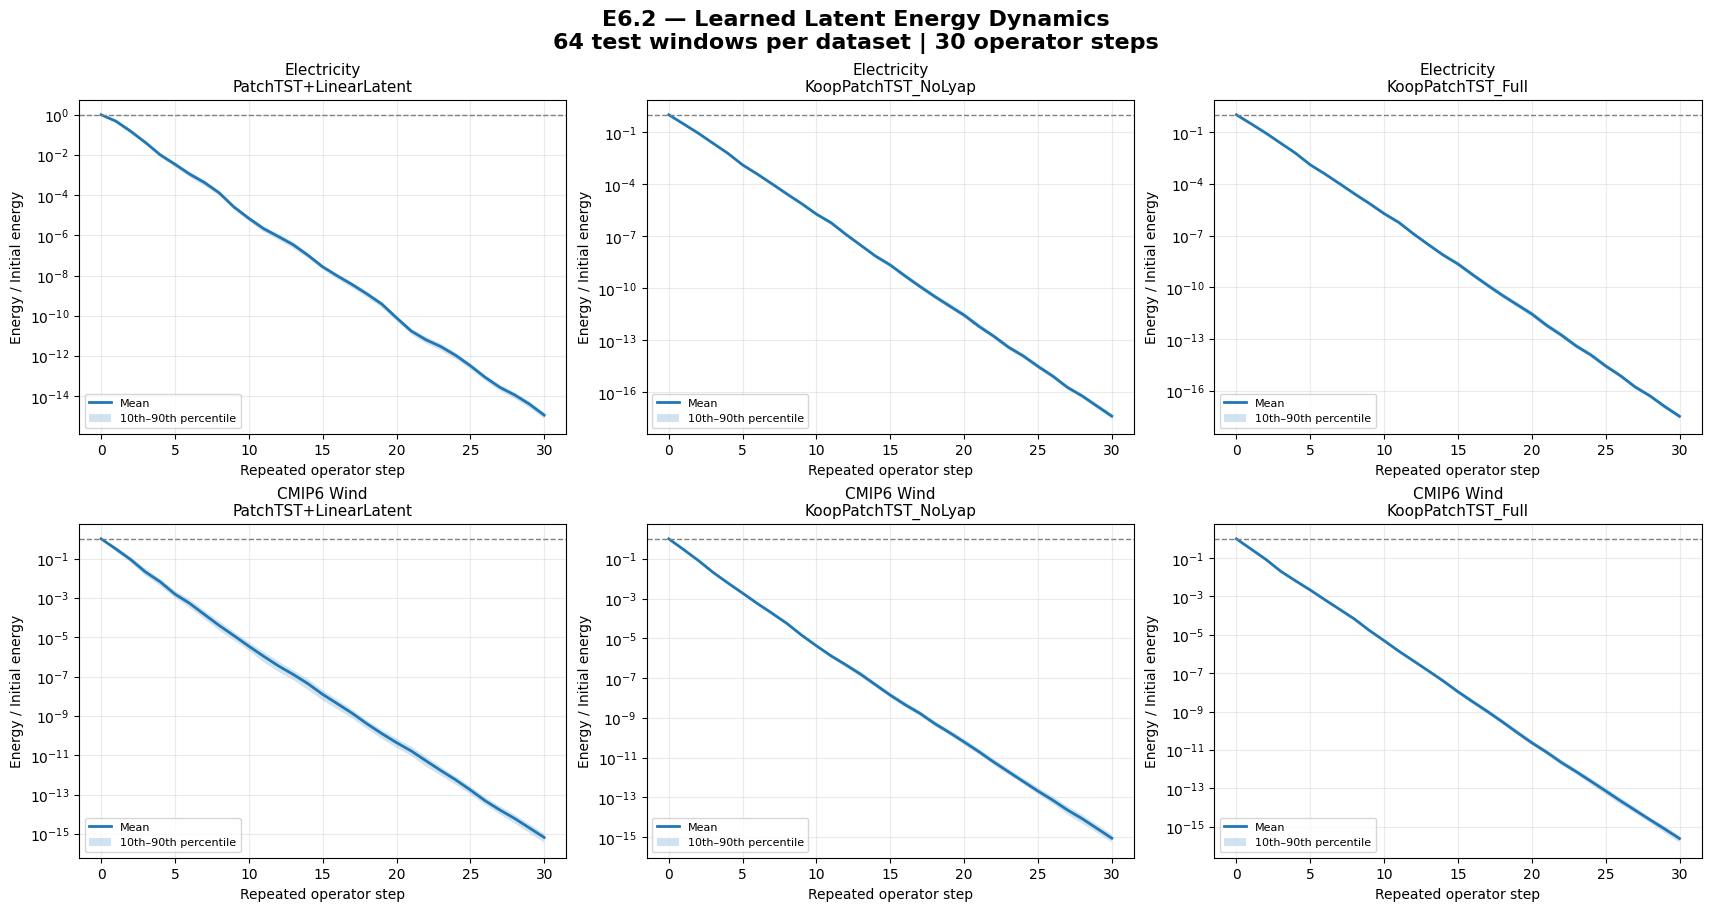


=== E6.2 VALIDATION ===
Checkpoints: 6
Test windows per dataset: 64
Rollout steps: 30
Dynamics rows: 11904
Training performed: 0
Saved: fig03_e6_latent_energy_dynamics.png

E6.2 LATENT DYNAMICS PASSED!


In [4]:
import ast
import json
import hashlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Reuse PROJECT, DATASETS, MODELS,
# ABLATION_RESULTS, E6_RESULTS, E6_SPECTRA
# from previous cells.

MODEL_NOTEBOOK = (
    PROJECT / "experiments" / "05_ablation"
    / "02_ablation_model.ipynb"
)

DATA_DIR = (
    PROJECT / "experiments" / "05_ablation" / "data"
)

DATA_FILES = {
    "Electricity": "electricity_ablation.pt",
    "CMIP6 Wind": "cmip6_wind_ablation.pt"
}

CLASS_NAMES = {
    "_orth",
    "StrictStableKoopmanOperator",
    "LinearLatentPropagator",
    "SinCosPosEnc",
    "PatchEmbed1D",
    "PatchTST_Backbone",
    "PatchTST_UnconstrainedLatent",
    "Koopformer_PatchTST"
}

SAMPLES_PER_DATASET = 64
ROLLOUT_STEPS = 30


# ------------------------------------------------------------
# 1. Load original model definitions only
#    (no notebook training cells executed)
# ------------------------------------------------------------

notebook = json.loads(
    MODEL_NOTEBOOK.read_text(encoding="utf-8")
)

definitions = []
found = set()

for cell in notebook["cells"]:

    if cell["cell_type"] != "code":
        continue

    source = cell["source"]

    if isinstance(source, list):
        source = "".join(source)

    tree = ast.parse(source)

    for node in tree.body:

        if isinstance(
            node, (ast.ClassDef, ast.FunctionDef)
        ) and node.name in CLASS_NAMES:

            assert node.name not in found

            definitions.append(node)
            found.add(node.name)

assert found == CLASS_NAMES

namespace = {
    "torch": torch,
    "nn": nn,
    "np": np
}

module_ast = ast.fix_missing_locations(
    ast.Module(
        body=definitions,
        type_ignores=[]
    )
)

exec(
    compile(module_ast, str(MODEL_NOTEBOOK), "exec"),
    namespace
)

print("Original model definitions loaded:", len(found))


# ------------------------------------------------------------
# 2. Read test bundles and verify training data hash
# ------------------------------------------------------------

def safe_load(path):
    return torch.load(
        path, map_location="cpu",
        weights_only=True
    )


def bundle_digest(bundle):

    digest = hashlib.sha256()

    for split in ("train", "test"):

        tensor = (
            bundle[split]
            .detach()
            .cpu()
            .contiguous()
        )

        digest.update(split.encode())
        digest.update(
            str(tuple(tensor.shape)).encode()
        )
        digest.update(
            tensor.numpy().tobytes()
        )

    return digest.hexdigest()


DATA_BUNDLES = {}
DATA_HASHES = {}

for dataset in DATASETS:

    path = DATA_DIR / DATA_FILES[dataset]

    assert path.is_file(), path

    bundle = safe_load(path)

    assert (
        bundle["test"].shape[1]
        == bundle["input_dim"]
    )

    DATA_BUNDLES[dataset] = bundle
    DATA_HASHES[dataset] = bundle_digest(bundle)

    print(
        dataset,
        "test shape:",
        tuple(bundle["test"].shape)
    )


# ------------------------------------------------------------
# 3. Construct deterministic test windows
# ------------------------------------------------------------

TEST_WINDOWS = {}
TEST_INDICES = {}

for dataset in DATASETS:

    series = (
        DATA_BUNDLES[dataset]["test"]
        .detach()
        .cpu()
        .float()
    )

    n_windows = len(series) - P - H

    assert n_windows >= SAMPLES_PER_DATASET

    indices = np.linspace(
        0,
        n_windows - 1,
        SAMPLES_PER_DATASET,
        dtype=int
    )

    assert len(np.unique(indices)) == 64

    X = torch.stack([
        series[int(i):int(i) + P]
        for i in indices
    ])

    assert X.shape == (
        SAMPLES_PER_DATASET,
        P,
        int(DATA_BUNDLES[dataset]["input_dim"])
    )

    TEST_WINDOWS[dataset] = X
    TEST_INDICES[dataset] = indices


# ------------------------------------------------------------
# 4. Load trained model and extract real latent states
# ------------------------------------------------------------

def make_inference_model(dataset, model_name):

    if model_name == "PatchTST+LinearLatent":
        cls = namespace[
            "PatchTST_UnconstrainedLatent"
        ]
    else:
        cls = namespace[
            "Koopformer_PatchTST"
        ]

    input_dim = int(
        DATA_BUNDLES[dataset]["input_dim"]
    )

    model = cls(
        input_dim=input_dim,
        seq_len=P,
        horizon=H,
        patch_len=P,
        d_model=96
    )

    path = (
        ABLATION_RESULTS
        / f"{slug(dataset)}_grid_search_e4000"
        / f"{slug(model_name)}_p{P}_h{H}_d96.pt"
    )

    artifact = safe_load(path)
    cfg = artifact["config"]

    assert cfg["dataset"] == dataset
    assert cfg["model"] == model_name
    assert int(cfg["p"]) == P
    assert int(cfg["h"]) == H
    assert int(cfg["epochs"]) == EPOCHS
    assert int(cfg["seed"]) == SEED
    assert int(cfg["d_model"]) == 96

    assert (
        cfg["processed_sha256"]
        == DATA_HASHES[dataset]
    ), f"Processed data hash mismatch: {dataset}"

    model.load_state_dict(
        artifact["model_state_dict"],
        strict=True
    )

    model.eval()

    return model


# ------------------------------------------------------------
# 5. Simulate learned latent dynamics
# ------------------------------------------------------------

dynamics_rows = []
summary_rows = []

for dataset in DATASETS:
    for model_name in MODELS:

        model = make_inference_model(
            dataset, model_name
        )

        X = TEST_WINDOWS[dataset]

        with torch.inference_mode():

            pred, z0, z_next = model(
                X, return_latents=True
            )

        assert z0.shape == (64, 96)
        assert torch.isfinite(z0).all()

        # Matrix obtained from E6.1 analysis
        K = torch.from_numpy(
            E6_SPECTRA[
                (dataset, model_name)
            ]["K"]
        ).double()

        Z = z0.detach().double()

        # Verify the analyzed operator matches
        # the loaded trained model's forward pass.
        torch.testing.assert_close(
            Z @ K.T,
            z_next.detach().double(),
            rtol=3e-5,
            atol=3e-5
        )

        initial_energy = (
            Z.square().sum(dim=1)
        )

        assert (initial_energy > 1e-14).all()

        previous_energy = None
        increase_count = 0
        samples_with_increase = set()
        maximum_ratio = 1.0

        for step in range(ROLLOUT_STEPS + 1):

            energy = Z.square().sum(dim=1)
            norm = torch.sqrt(energy)

            relative_energy = (
                energy / initial_energy
            )

            relative_norm = (
                norm / torch.sqrt(initial_energy)
            )

            maximum_ratio = max(
                maximum_ratio,
                float(relative_energy.max())
            )

            if previous_energy is None:
                delta_normalized = torch.zeros_like(
                    energy
                )
            else:
                delta_normalized = (
                    energy - previous_energy
                ) / initial_energy

            for j, sample_index in enumerate(
                TEST_INDICES[dataset]
            ):

                delta_value = float(
                    delta_normalized[j]
                )

                if step > 0 and delta_value > 1e-12:
                    increase_count += 1
                    samples_with_increase.add(j)

                dynamics_rows.append({
                    "Dataset": dataset,
                    "Model": model_name,
                    "Sample_Index": int(sample_index),
                    "Step": step,
                    "Latent_Norm": float(norm[j]),
                    "Latent_Energy": float(energy[j]),
                    "Relative_Norm": float(
                        relative_norm[j]
                    ),
                    "Relative_Energy": float(
                        relative_energy[j]
                    ),
                    "Delta_Energy_Normalized":
                        delta_value,
                    "Lyapunov_Violation_Normalized":
                        max(0.0, delta_value)
                })

            previous_energy = energy

            if step < ROLLOUT_STEPS:
                Z = Z @ K.T

        final_energy_ratio = (
            Z.square().sum(dim=1)
            / initial_energy
        )

        summary_rows.append({
            "Dataset": dataset,
            "Model": model_name,
            "Samples": SAMPLES_PER_DATASET,
            "Rollout_Steps": ROLLOUT_STEPS,
            "Energy_Increase_Transitions":
                increase_count,
            "Samples_With_Energy_Increase":
                len(samples_with_increase),
            "Max_Relative_Energy":
                maximum_ratio,
            "Mean_Final_Relative_Energy":
                float(final_energy_ratio.mean())
        })

        del model


# ------------------------------------------------------------
# 6. Export and validate
# ------------------------------------------------------------

LATENT_DYNAMICS = pd.DataFrame(
    dynamics_rows
)

LATENT_SUMMARY = pd.DataFrame(
    summary_rows
)

assert len(LATENT_DYNAMICS) == (
    2 * 3 * 64 * 31
)

assert len(LATENT_SUMMARY) == 6

assert np.isfinite(
    LATENT_DYNAMICS[
        ["Latent_Norm", "Latent_Energy",
         "Relative_Norm", "Relative_Energy"]
    ].to_numpy()
).all()

# Koopman variants must be contractive
koop_summary = LATENT_SUMMARY[
    LATENT_SUMMARY["Model"]
    != "PatchTST+LinearLatent"
]

assert (
    koop_summary["Energy_Increase_Transitions"] == 0
).all()

LATENT_DYNAMICS.to_csv(
    E6_RESULTS / "latent_dynamics.csv",
    index=False
)

LATENT_SUMMARY.to_csv(
    E6_RESULTS / "latent_dynamics_summary.csv",
    index=False
)

print("\n=== E6.2 LATENT DYNAMICS SUMMARY ===")
display(LATENT_SUMMARY.round(8))


# ------------------------------------------------------------
# 7. Figure 3 — Normalized Latent Energy
# ------------------------------------------------------------

FIGURE_DIR = E6_RESULTS / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 9),
    constrained_layout=True
)

model_order = MODELS

for i, dataset in enumerate(DATASETS):
    for j, model_name in enumerate(model_order):

        ax = axes[i, j]

        sub = LATENT_DYNAMICS[
            (LATENT_DYNAMICS["Dataset"] == dataset)
            & (LATENT_DYNAMICS["Model"] == model_name)
        ]

        grouped = sub.groupby("Step")[
            "Relative_Energy"
        ]

        mean = grouped.mean()
        q10 = grouped.quantile(0.10)
        q90 = grouped.quantile(0.90)

        steps = mean.index.to_numpy()

        ax.plot(
            steps,
            mean.to_numpy(),
            linewidth=2,
            label="Mean"
        )

        ax.fill_between(
            steps,
            q10.to_numpy(),
            q90.to_numpy(),
            alpha=0.20,
            label="10th–90th percentile"
        )

        ax.axhline(
            1.0,
            linestyle="--",
            color="gray",
            linewidth=1
        )

        ax.set_yscale("log")
        ax.set_xlabel("Repeated operator step")
        ax.set_ylabel("Energy / Initial energy")

        ax.set_title(
            f"{dataset}\n{model_name}",
            fontsize=11
        )

        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

fig.suptitle(
    "E6.2 — Learned Latent Energy Dynamics\n"
    "64 test windows per dataset | 30 operator steps",
    fontsize=16,
    fontweight="bold"
)

FIG03_PATH = (
    FIGURE_DIR
    / "fig03_e6_latent_energy_dynamics.png"
)

fig.savefig(
    FIG03_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert FIG03_PATH.is_file()

print("\n=== E6.2 VALIDATION ===")
print("Checkpoints:", 6)
print("Test windows per dataset:", 64)
print("Rollout steps:", ROLLOUT_STEPS)
print("Dynamics rows:", len(LATENT_DYNAMICS))
print("Training performed: 0")
print("Saved:", FIG03_PATH.name)
print("\nE6.2 LATENT DYNAMICS PASSED!")


E6.3: Lyapunov Regularization Analysis

=== E6.3 LYAPUNOV ANALYSIS ===


,Dataset,Model,Worst_Unit_Delta_V,Mean_OneStep_Relative_Delta,Max_OneStep_Relative_Delta,Positive_Test_Transitions,Train_Weighted_Lyap_Max,Train_Nonzero_Lyap_Epochs
0,Electricity,PatchTST+LinearLatent,0.387332,-0.518951,-0.376225,0,NaN,NaN
1,Electricity,KoopPatchTST_NoLyap,-0.209110,-0.702270,-0.651651,0,NaN,NaN
2,Electricity,KoopPatchTST_Full,-0.209067,-0.701382,-0.651993,0,0.0,0.0
3,CMIP6 Wind,PatchTST+LinearLatent,0.325851,-0.692108,-0.397596,0,NaN,NaN
4,CMIP6 Wind,KoopPatchTST_NoLyap,-0.233101,-0.708558,-0.619961,0,NaN,NaN
5,CMIP6 Wind,KoopPatchTST_Full,-0.233452,-0.708961,-0.634285,0,0.0,0.0



=== FULL TRAINING PENALTY AUDIT ===
Electricity | epochs = 4000 | max penalty = 0.0 | nonzero epochs = 0
CMIP6 Wind | epochs = 4000 | max penalty = 0.0 | nonzero epochs = 0


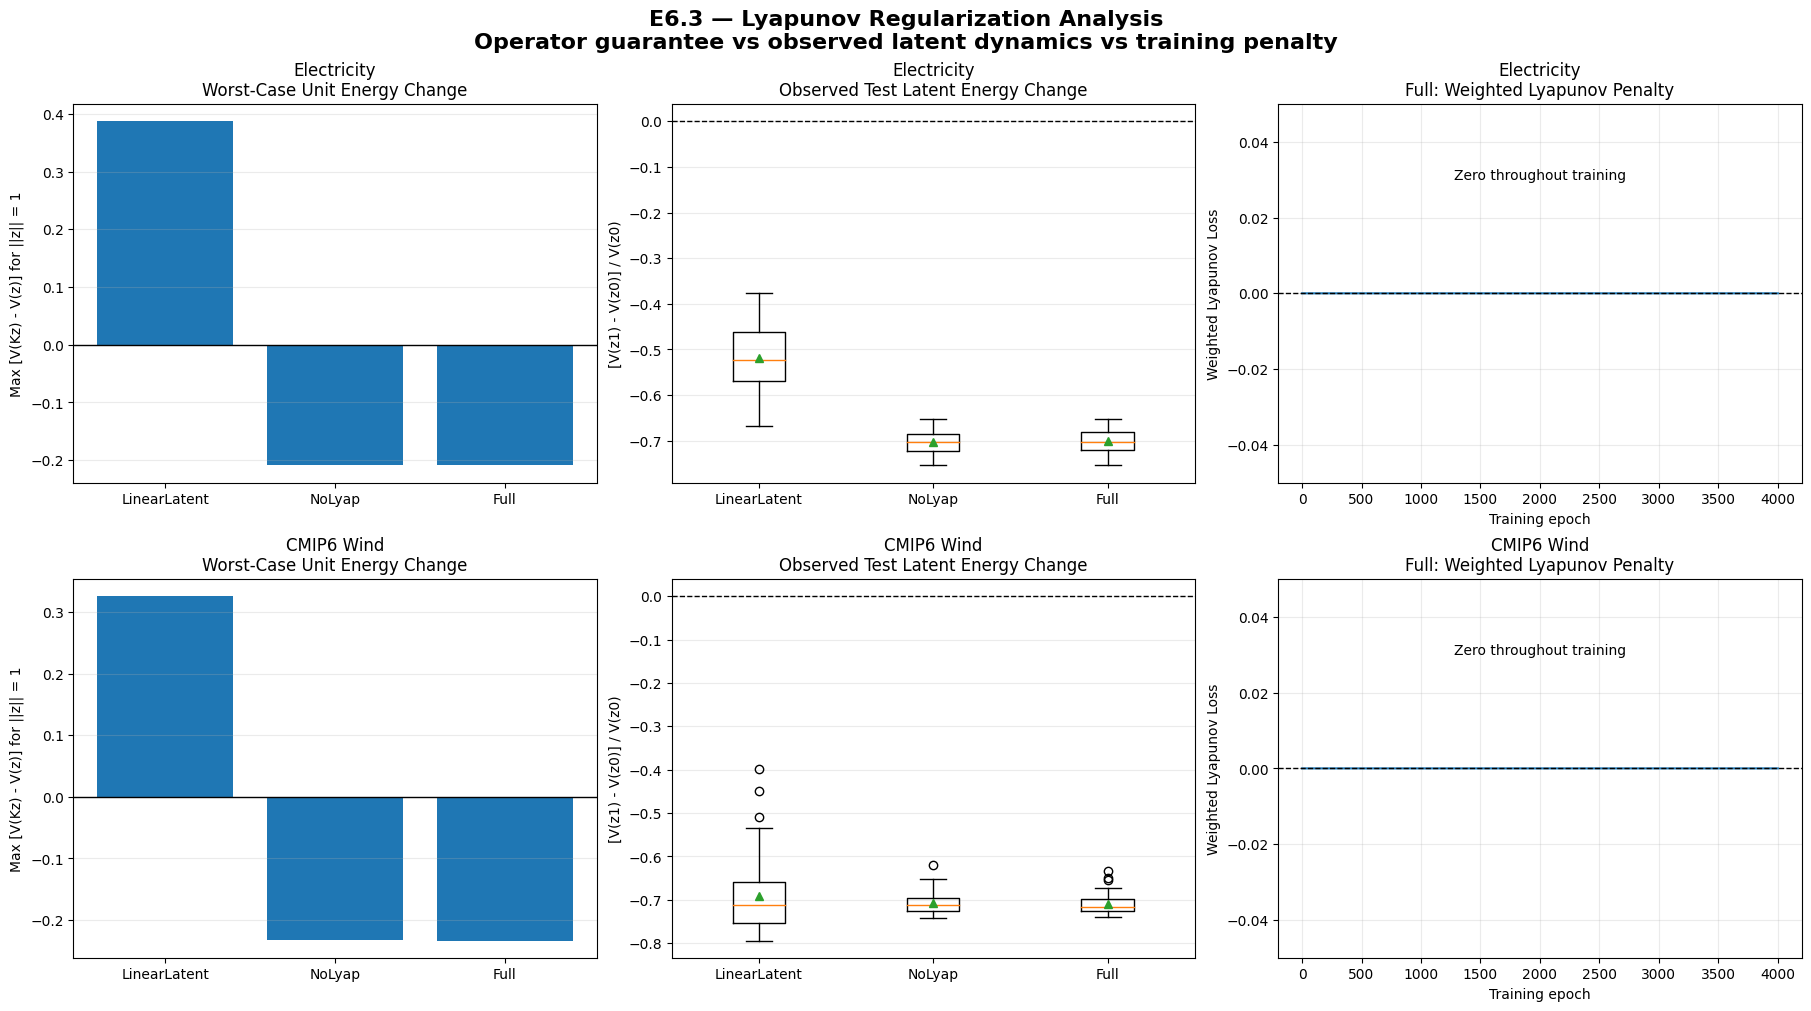


=== E6.3 VALIDATION ===
Operators analyzed: 6
Full training histories: 2
Training performed: 0
CSV: lyapunov_metrics.csv
Figure: fig04_e6_lyapunov_analysis.png

E6.3 LYAPUNOV ANALYSIS PASSED!


In [5]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Reuse from previous E6 cells:
# DATASETS, MODELS, P, H, SEED, EPOCHS
# ABLATION_RESULTS, E6_RESULTS, FIGURE_DIR
# OPERATOR_METRICS, LATENT_DYNAMICS, slug()

MODEL_ORDER = [
    "PatchTST+LinearLatent",
    "KoopPatchTST_NoLyap",
    "KoopPatchTST_Full"
]

SHORT_LABELS = [
    "LinearLatent",
    "NoLyap",
    "Full"
]

LYAP_HISTORY = {}
LYAP_ROWS = []

# ------------------------------------------------------------
# 1. Audit the quadratic Lyapunov condition
#    V(z) = ||z||_2^2
#    Delta V = V(Kz) - V(z)
# ------------------------------------------------------------

for dataset in DATASETS:
    for model in MODEL_ORDER:

        op_row = OPERATOR_METRICS[
            (OPERATOR_METRICS["Dataset"] == dataset)
            & (OPERATOR_METRICS["Model"] == model)
        ]

        assert len(op_row) == 1

        sigma_max = float(
            op_row["Sigma_Max"].iloc[0]
        )

        # Exact worst-case over unit vectors
        worst_case_delta = sigma_max**2 - 1

        # ----------------------------------------------------
        # 2. Observed one-step changes on real test latents
        # ----------------------------------------------------

        sub = LATENT_DYNAMICS[
            (LATENT_DYNAMICS["Dataset"] == dataset)
            & (LATENT_DYNAMICS["Model"] == model)
        ]

        initial = (
            sub[sub["Step"] == 0]
            .set_index("Sample_Index")
            .sort_index()
        )

        step1 = (
            sub[sub["Step"] == 1]
            .set_index("Sample_Index")
            .sort_index()
        )

        assert len(initial) == 64
        assert len(step1) == 64
        assert initial.index.equals(step1.index)

        E0 = initial[
            "Latent_Energy"
        ].to_numpy(dtype=float)

        E1 = step1[
            "Latent_Energy"
        ].to_numpy(dtype=float)

        assert np.all(E0 > 0)

        relative_delta = (E1 - E0) / E0

        # Positive normalized energy increases,
        # with the same threshold used in E6.2
        positive_count = int(
            np.sum(relative_delta > 1e-12)
        )

        # Unweighted empirical Lyapunov violation
        observed_violation = np.maximum(
            E1 - E0, 0.0
        )

        # ----------------------------------------------------
        # 3. Check Full model's training Lyapunov history
        # ----------------------------------------------------

        train_lyap_max = np.nan
        train_nonzero_epochs = np.nan

        if model == "KoopPatchTST_Full":

            path = (
                ABLATION_RESULTS
                / f"{slug(dataset)}_grid_search_e4000"
                / f"{slug(model)}_p{P}_h{H}_d96.pt"
            )

            artifact = torch.load(
                path,
                map_location="cpu",
                weights_only=True
            )

            cfg = artifact["config"]

            assert cfg["dataset"] == dataset
            assert cfg["model"] == model
            assert int(cfg["p"]) == P
            assert int(cfg["h"]) == H
            assert int(cfg["epochs"]) == EPOCHS
            assert int(cfg["seed"]) == SEED
            assert np.isclose(
                float(cfg["lyap_weight"]),
                0.1
            )

            history = torch.as_tensor(
                artifact["lyap_history"]
            ).detach().cpu().numpy()

            assert history.shape == (4000,)
            assert np.isfinite(history).all()

            LYAP_HISTORY[dataset] = history

            train_lyap_max = float(
                np.max(np.abs(history))
            )

            train_nonzero_epochs = int(
                np.sum(np.abs(history) > 1e-12)
            )

            del artifact

        LYAP_ROWS.append({
            "Dataset": dataset,
            "Model": model,
            "Sigma_Max": sigma_max,
            "Worst_Unit_Delta_V": worst_case_delta,
            "Contractive": sigma_max < 1,
            "Test_Samples": len(E0),
            "Mean_OneStep_Relative_Delta":
                float(relative_delta.mean()),
            "Max_OneStep_Relative_Delta":
                float(relative_delta.max()),
            "Positive_Test_Transitions":
                positive_count,
            "Max_Test_Lyap_Violation":
                float(observed_violation.max()),
            "Train_Weighted_Lyap_Max":
                train_lyap_max,
            "Train_Nonzero_Lyap_Epochs":
                train_nonzero_epochs
        })


# ------------------------------------------------------------
# 4. Validation and CSV export
# ------------------------------------------------------------

E6_LYAP_SUMMARY = pd.DataFrame(LYAP_ROWS)

assert len(E6_LYAP_SUMMARY) == 6
assert len(LYAP_HISTORY) == 2

# Stable Koopman models must be contractive
stable_rows = E6_LYAP_SUMMARY[
    E6_LYAP_SUMMARY["Model"].isin([
        "KoopPatchTST_NoLyap",
        "KoopPatchTST_Full"
    ])
]

assert stable_rows["Contractive"].all()

assert (
    stable_rows["Positive_Test_Transitions"] == 0
).all()

OUTPUT = (
    E6_RESULTS / "lyapunov_metrics.csv"
)

E6_LYAP_SUMMARY.to_csv(
    OUTPUT,
    index=False
)

print("=== E6.3 LYAPUNOV ANALYSIS ===")

display(
    E6_LYAP_SUMMARY[[
        "Dataset",
        "Model",
        "Worst_Unit_Delta_V",
        "Mean_OneStep_Relative_Delta",
        "Max_OneStep_Relative_Delta",
        "Positive_Test_Transitions",
        "Train_Weighted_Lyap_Max",
        "Train_Nonzero_Lyap_Epochs"
    ]]
)

print("\n=== FULL TRAINING PENALTY AUDIT ===")

for dataset, history in LYAP_HISTORY.items():

    print(
        dataset,
        "| epochs =", len(history),
        "| max penalty =", np.max(np.abs(history)),
        "| nonzero epochs =",
        np.sum(np.abs(history) > 1e-12)
    )


# ------------------------------------------------------------
# 5. Figure 4 — Theoretical vs observed stability
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10),
    constrained_layout=True
)

for row, dataset in enumerate(DATASETS):

    subset = E6_LYAP_SUMMARY[
        E6_LYAP_SUMMARY["Dataset"] == dataset
    ].set_index("Model").loc[MODEL_ORDER]

    # A. Worst-case quadratic energy change
    ax = axes[row, 0]

    ax.bar(
        SHORT_LABELS,
        subset["Worst_Unit_Delta_V"].to_numpy()
    )

    ax.axhline(0, color="black", linewidth=1)

    ax.set_title(
        f"{dataset}\nWorst-Case Unit Energy Change"
    )

    ax.set_ylabel(
        "Max [V(Kz) - V(z)] for ||z|| = 1"
    )

    ax.grid(axis="y", alpha=0.25)

    # B. Empirical one-step energy change
    ax = axes[row, 1]

    sample_deltas = []

    for model in MODEL_ORDER:

        sample = LATENT_DYNAMICS[
            (LATENT_DYNAMICS["Dataset"] == dataset)
            & (LATENT_DYNAMICS["Model"] == model)
            & (LATENT_DYNAMICS["Step"] == 1)
        ]

        assert len(sample) == 64

        sample_deltas.append(
            sample[
                "Delta_Energy_Normalized"
            ].to_numpy()
        )

    ax.boxplot(
        sample_deltas,
        labels=SHORT_LABELS,
        showmeans=True
    )

    ax.axhline(
        0,
        linestyle="--",
        color="black",
        linewidth=1
    )

    ax.set_title(
        f"{dataset}\nObserved Test Latent Energy Change"
    )

    ax.set_ylabel(
        "[V(z1) - V(z0)] / V(z0)"
    )

    ax.grid(axis="y", alpha=0.25)

    # C. Full training Lyapunov penalty
    ax = axes[row, 2]

    history = LYAP_HISTORY[dataset]

    ax.plot(
        np.arange(1, 4001),
        history,
        linewidth=1.5
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"{dataset}\nFull: Weighted Lyapunov Penalty"
    )

    ax.set_xlabel("Training epoch")
    ax.set_ylabel("Weighted Lyapunov Loss")
    ax.grid(alpha=0.25)

    if np.all(history == 0):

        ax.set_ylim(-0.05, 0.05)

        ax.text(
            0.5, 0.8,
            "Zero throughout training",
            transform=ax.transAxes,
            ha="center"
        )


fig.suptitle(
    "E6.3 — Lyapunov Regularization Analysis\n"
    "Operator guarantee vs observed latent dynamics "
    "vs training penalty",
    fontsize=16,
    fontweight="bold"
)

FIG04_PATH = (
    FIGURE_DIR
    / "fig04_e6_lyapunov_analysis.png"
)

fig.savefig(
    FIG04_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert FIG04_PATH.is_file()

print("\n=== E6.3 VALIDATION ===")
print("Operators analyzed:", len(E6_LYAP_SUMMARY))
print("Full training histories:", len(LYAP_HISTORY))
print("Training performed: 0")
print("CSV:", OUTPUT.name)
print("Figure:", FIG04_PATH.name)

print("\nE6.3 LYAPUNOV ANALYSIS PASSED!")
